# Tensors
- defined by:
    - rank: number of dimensions
    - shape: number of elements in each dimension
    - data type: int, float, str, etc.

# Regression Exercise - Auto Price

In [1]:
import torch
import torch.utils.data as data_utils
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import hiddenlayer as hl

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline

In [3]:
df_auto = pd.read_csv(r"C:\Users\Andrew\OneDrive\Desktop\PluraSight\PyTorch\4 Deep Learning Models\datasets\Automobile_data.csv")
df_auto.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
symboling,205.0,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
wheel-base,205.0,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9
length,205.0,174.049268,12.337289,141.1,166.3,173.2,183.1,208.1
width,205.0,65.907805,2.145204,60.3,64.1,65.5,66.9,72.3
height,205.0,53.724878,2.443522,47.8,52.0,54.1,55.5,59.8
curb-weight,205.0,2555.565854,520.680204,1488.0,2145.0,2414.0,2935.0,4066.0
engine-size,205.0,126.907317,41.642693,61.0,97.0,120.0,141.0,326.0
compression-ratio,205.0,10.142537,3.972040,7.0,8.6,9.0,9.4,23.0
city-mpg,205.0,25.219512,6.542142,13.0,19.0,24.0,30.0,49.0
highway-mpg,205.0,30.751220,6.886443,16.0,25.0,30.0,34.0,54.0


In [6]:
df_auto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       205 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [9]:
for col in df_auto.columns:
    cnt = (df_auto[col]=='?').sum()
    if cnt > 0:
        print(f"{col} has {cnt} missing values")

normalized-losses has 41 missing values
num-of-doors has 2 missing values
bore has 4 missing values
stroke has 4 missing values
horsepower has 2 missing values
peak-rpm has 2 missing values
price has 4 missing values


In [12]:
df_auto = df_auto.replace('?', np.nan)
for col in df_auto.columns:
    cnt = (df_auto[col]=='?').sum()
    if cnt > 0:
        print(f"{col} has {cnt} missing values")

In [13]:
df_auto = df_auto.dropna()

In [27]:
df_auto['horsepower'] = df_auto['horsepower'].astype(float)
features_col = ['make', 'fuel-type', 'body-style', 'horsepower']
X = df_auto[features_col]
Y = df_auto['price'].astype(float)

In [28]:
X = pd.get_dummies(X, columns=['make', 'fuel-type', 'body-style'], drop_first=True, dtype=float)

In [29]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 159 entries, 3 to 204
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horsepower            159 non-null    float64
 1   make_bmw              159 non-null    float64
 2   make_chevrolet        159 non-null    float64
 3   make_dodge            159 non-null    float64
 4   make_honda            159 non-null    float64
 5   make_jaguar           159 non-null    float64
 6   make_mazda            159 non-null    float64
 7   make_mercedes-benz    159 non-null    float64
 8   make_mitsubishi       159 non-null    float64
 9   make_nissan           159 non-null    float64
 10  make_peugot           159 non-null    float64
 11  make_plymouth         159 non-null    float64
 12  make_porsche          159 non-null    float64
 13  make_saab             159 non-null    float64
 14  make_subaru           159 non-null    float64
 15  make_toyota           159 no

In [30]:
X['horsepower'] = StandardScaler().fit_transform(X[['horsepower']])

In [31]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [33]:
X_train_ts = torch.tensor(X_train.values, dtype=torch.float)
X_test_ts = torch.tensor(X_test.values, dtype=torch.float)
Y_train_ts = torch.tensor(Y_train.values, dtype=torch.float).view(-1, 1)
Y_test_ts = torch.tensor(Y_test.values, dtype=torch.float).view(-1, 1)

X_train_ts.shape, X_test_ts.shape, Y_train_ts.shape, Y_test_ts.shape

(torch.Size([127, 23]),
 torch.Size([32, 23]),
 torch.Size([127, 1]),
 torch.Size([32, 1]))

In [42]:
inp = X_train_ts.shape[1]
hidden = 100
out = 1
loss_fn = torch.nn.MSELoss()
lr = 1e-2

In [43]:
model = torch.nn.Sequential(
    torch.nn.Linear(inp, hidden),
    torch.nn.Sigmoid(),
    torch.nn.Linear(hidden, out),
)

In [44]:
# training
for i in range(10000):
    Y_pred = model(X_train_ts)
    loss = loss_fn(Y_pred, Y_train_ts)
    if i % 1000 == 0:
        print(f"Epoch {i}: train loss: {loss.item()}")
    model.zero_grad()
    loss.backward()
    with torch.no_grad():
        for param in model.parameters():
            param -= lr * param.grad

Epoch 0: train loss: 173561808.0
Epoch 1000: train loss: 7029351.5
Epoch 2000: train loss: 6115378.5
Epoch 3000: train loss: 7929754.0
Epoch 4000: train loss: 7250392.5
Epoch 5000: train loss: 7065095.5
Epoch 6000: train loss: 6957769.5
Epoch 7000: train loss: 6886162.5
Epoch 8000: train loss: 6833947.5
Epoch 9000: train loss: 6794606.0


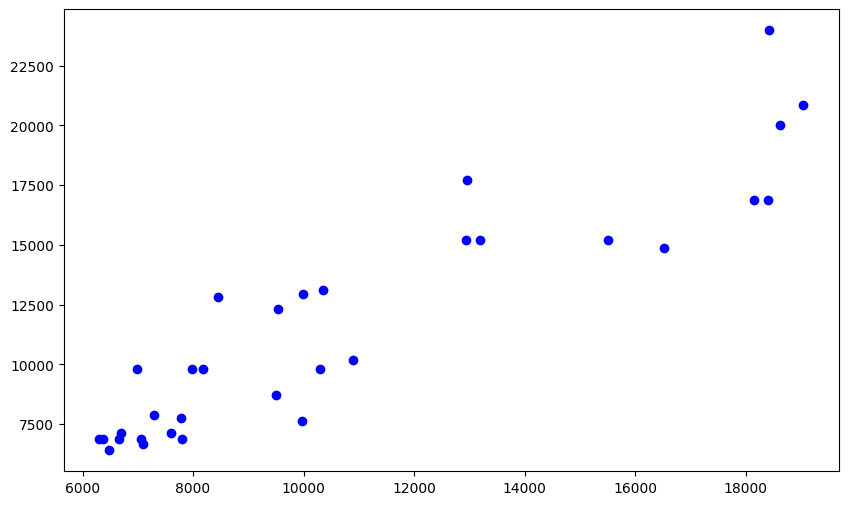

In [47]:
Y_pred_ts = model(X_test_ts)
y_pred = Y_pred_ts.detach().numpy()

plt.figure(figsize=(10, 6))
plt.scatter(Y_test.values, y_pred, color='blue', label='Model Prediction')
plt.show()

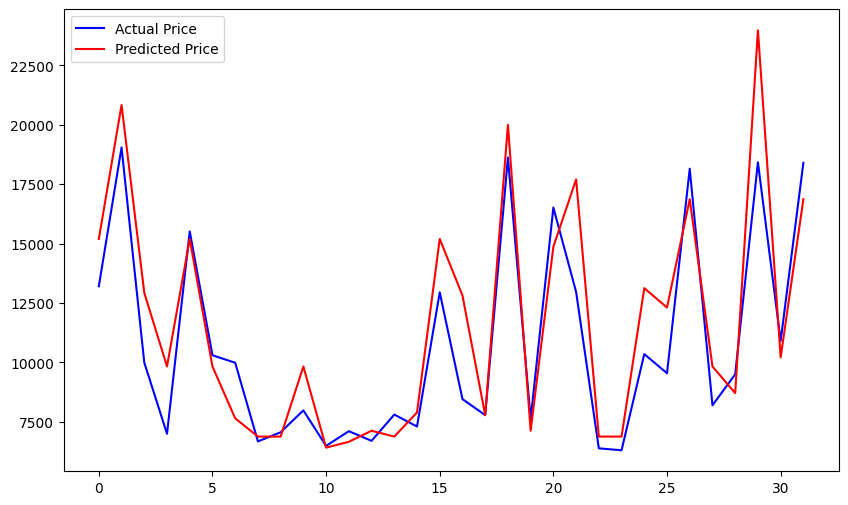

In [51]:
plt.figure(figsize=(10, 6))
plt.plot(Y_test.values, color='blue', label='Actual Price')
plt.plot(y_pred, color='red', label='Predicted Price')
plt.legend()
plt.show()

# Classification Exercise - Titanic

In [4]:
df_titanic = pd.read_csv(r'd:\PluraSight\PyTorch\4 Deep Learning Models\datasets\titanic_data\train.csv')
df_titanic.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [5]:
unwanted_features = ['PassengerId', 'Name', 'Ticket', 
                     'Cabin', 'SibSp', 'Parch','Embarked']
df_titanic = df_titanic.drop(unwanted_features, axis=1)
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   Fare      891 non-null    float64
dtypes: float64(2), int64(2), object(1)
memory usage: 34.9+ KB


In [6]:
df_titanic = pd.get_dummies(df_titanic, columns=['Sex', 'Pclass'], drop_first=True, dtype=float)
df_titanic = df_titanic.dropna()
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  714 non-null    int64  
 1   Age       714 non-null    float64
 2   Fare      714 non-null    float64
 3   Sex_male  714 non-null    float64
 4   Pclass_2  714 non-null    float64
 5   Pclass_3  714 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 39.0 KB


In [7]:
X = df_titanic.drop('Survived', axis=1)
Y = df_titanic['Survived']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((571, 5), (143, 5), (571,), (143,))

In [8]:
X_train_ts = torch.tensor(X_train.values, dtype=torch.float)
X_test_ts = torch.tensor(X_test.values, dtype=torch.float)
Y_train_ts = torch.tensor(Y_train.values, dtype=torch.long)
Y_test_ts = torch.tensor(Y_test.values, dtype=torch.long)

X_train_ts.shape, X_test_ts.shape, Y_train_ts.shape, Y_test_ts.shape

(torch.Size([571, 5]),
 torch.Size([143, 5]),
 torch.Size([571]),
 torch.Size([143]))

In [9]:
inp = X_train_ts.shape[1]
hidden = 10
out = len(Y_train_ts.unique())

In [10]:
class TitanicModel(nn.Module):
    def __init__(self):
        super(TitanicModel, self).__init__()
        self.fc1 = nn.Linear(inp, hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.fc3 = nn.Linear(hidden, out)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.sigmoid(self.fc2(x))
        x = self.fc3(x)

        return F.log_softmax(x, dim=-1)
    

In [11]:
model = TitanicModel()
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.NLLLoss()
epoch_data = []
epoch = 1000

for i in range(epoch):
    Y_pred = model(X_train_ts)
    loss = loss_fn(Y_pred, Y_train_ts)
    model.zero_grad()
    loss.backward()
    optimizer.step()

    Y_pred_test = model(X_test_ts)
    test_loss = loss_fn(Y_pred_test, Y_test_ts)    

    _, pred = torch.max(Y_pred_test, 1)
    acc = accuracy_score(Y_test_ts, pred)
    epoch_data.append((i, loss.item(), test_loss.item(), acc))

    if i % 100 == 0:
        print(f"Epoch {i}: train loss: {loss.item()}, test loss: {test_loss.item()}, accuracy: {acc}")

Epoch 0: train loss: 0.7817621827125549, test loss: 0.7823466062545776, accuracy: 0.3916083916083916
Epoch 100: train loss: 0.6096761226654053, test loss: 0.6544336676597595, accuracy: 0.6223776223776224
Epoch 200: train loss: 0.5900137424468994, test loss: 0.6628080606460571, accuracy: 0.6293706293706294
Epoch 300: train loss: 0.5805428624153137, test loss: 0.6439170837402344, accuracy: 0.6363636363636364
Epoch 400: train loss: 0.5436895489692688, test loss: 0.5882281064987183, accuracy: 0.6573426573426573
Epoch 500: train loss: 0.4665071368217468, test loss: 0.5301088094711304, accuracy: 0.7552447552447552
Epoch 600: train loss: 0.42794013023376465, test loss: 0.5109995603561401, accuracy: 0.7482517482517482
Epoch 700: train loss: 0.4091204106807709, test loss: 0.5028145909309387, accuracy: 0.7342657342657343
Epoch 800: train loss: 0.39789852499961853, test loss: 0.5008348226547241, accuracy: 0.7412587412587412
Epoch 900: train loss: 0.3893955647945404, test loss: 0.48969733715057373

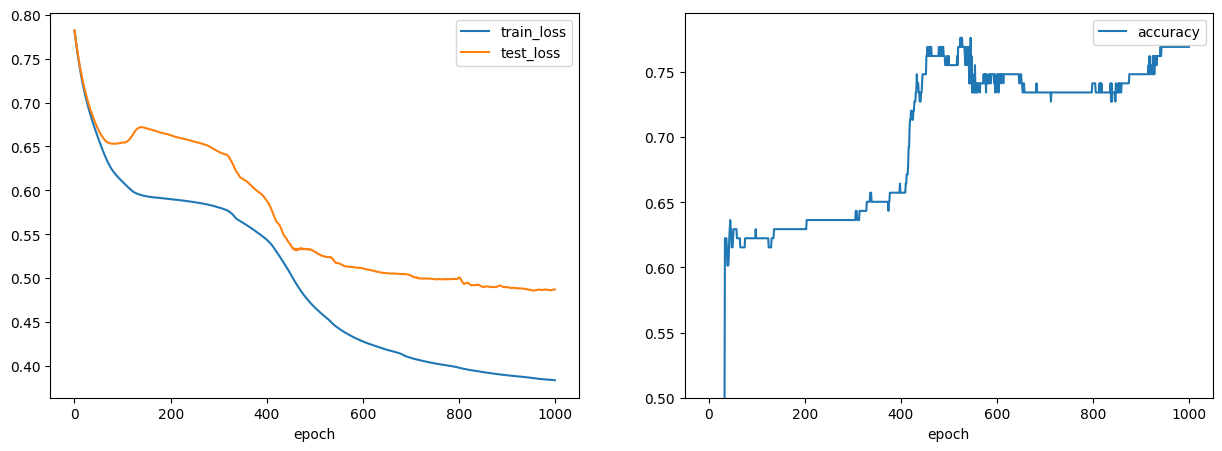

In [12]:
df_epoch = pd.DataFrame(epoch_data, columns=['epoch', 'train_loss', 'test_loss', 'accuracy'])
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
df_epoch.plot(x='epoch', y=['train_loss', 'test_loss'], ax=ax1)
df_epoch.plot(x='epoch', y='accuracy', ax=ax2)
plt.ylim(0.5)
plt.show()

In [15]:
Y_pred.shape, Y_pred_test.shape, Y_test_ts.shape

(torch.Size([571, 2]), torch.Size([143, 2]), torch.Size([143]))

# Convolutional Neural Networks (CNNs)
- Convolution layer: 
    - initial layers pick up on simplier patterns
    - local receptive field
- Pooling layer: 
    - subsequent layers pick up on more complexed abstractions
    - subsampling of inputs
    - neurons have no weights or biases
    - pooling neuron simply applies an aggregation function to all inputs (e.g., max)
- convolution: a sliding window function applied to an input matrix
    - slide convolutional kernel over the image matrix starting at the first position
    - kernel is a matrix function
        - the exact weights is determined during the training process
        - stride: distance btw successive receptive fields
    - CNN layers would allow to zoom in on specific bits of input
        - feature maps: convolutional layers generated by applying c. kernel to the input
        - neurons in c. layer are stimulated only by the input present in the local receptive fields 
        - not all neurons are connected to all pixels -> sparse NN
            - dense networks would suffer from param explosion
- architecture:
    - typically CNN is an alternating group of convolution and pooling layers
        - convolutional layers are usually followed by ReLU
    - inputs/outputs are images
        - successive outputs of pooling layers are smallers due to subsampling
        - outputs of convolutional layers are deeper and deeper due to extract more input features
    - outputs from CNN layers are fed to dense feed-forward layers (fully connected)
        - typically use ReLU activation
        - final softmax prediction layer
    - image (raw input) -> probabilities (softmax) -> final classification (highest p)
- batch normalization
    - used to mitigate vanishing or exploding gradients
        - vanishing: loss stuck at high level but gradients becomes zero and stops changing
        - exploding: sudden spike or drop in gradients across epoches
    - other tactics: 
        - proper initialization (e.g. Xavier & He)
        - non-saturating activation function (operates in active region)
        - gradient clipping (max/min gradient values)
    - use just before applying activation function
    - Steps:
        - normalize inputs (-mean / std)
        - scale (multipy by constant) and shift (add constant) inputs within a particular batch
    - built in support in PyTorch
    - other benefits:
        - allows much larger learning rate
        - reduces overfitting
        - speeds up convergence during training



# CNN Exercise - CIFAR-10 dataset

In [16]:
import torch
import torchvision
import torchvision.transforms as transforms

Data loader combines a dataset and provides single or multi-process iterators over the dataset
* <b>batch_size</b> = how many samples per batch to load (default: 1).<br>
* <b>shuffle = True</b>, to have the data reshuffled at every epoch <br>
* <b>num_workers= 2</b>, 2 subprocesses will be used for data loading.
0 means that the data will be loaded in the main process. (default: 0)

In [ ]:
trainset = torchvision.datasets.CIFAR10(root='./datasets',
                                        train=True,
                                        download=True,
                                        transform=transforms.ToTensor())

trainloader = torch.utils.data.DataLoader(trainset,
                                          batch_size=8,
                                          shuffle=True,
                                          num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./datasets',
                                       train=False,
                                       download=True,
                                       transform=transforms.ToTensor())

testloader = torch.utils.data.DataLoader(testset,
                                         batch_size=8,
                                         shuffle=False,
                                         num_workers=2)

In [ ]:
labels = ('plane', 'car', 'bird', 'cat','deer', 
          'dog', 'frog', 'horse', 'ship', 'truck')

In [ ]:
# Get a batch from the training data
#The DataLoader object divides the dataset into batches. 
# Here we examine the first batch of the training data set

images_batch, labels_batch = iter(trainloader).next()

In [ ]:
images_batch.shape

Configuring the neural network
* The input size will be the 3 channels of the images
* The first convolution will produce 16 channels
* The second convolution produces 32 channels
* The final output will have a size equal to the number of classes for the prediction
* The convolving kernel will have a size of 5

In [ ]:
in_size = 3
hid1_size = 16
hid2_size = 32
out_size = len(labels)
k_conv_size = 5 

Define the Convolutional Neural Network

<b>Conv2d: </b>Applies a 2D convolution over an input signal composed of several input planes.<br>
Parameters<br>
in_channels (int) – Number of channels in the input image<br>
out_channels (int) – Number of channels produced by the convolution<br>
kernel_size (int or tuple) – Size of the convolving kernel<br>

<b>BatchNorm2d: </b>Applies Batch Normalization over a 4D input (a mini-batch of 2D inputs with additional channel dimension) as described in the paper Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift .
Parameters<br>
num_features – C from an expected input of size (N,C,H,W)

<b>ReLU: </b>Activation function

<b>Maxpool2d: </b>
Parameters:<br>
kernel_size – the size of the window to take a max over

<b>Linear: </b>
Parameter:<br>

in_features: 
All the operations above used 4D Tensors of shape => torch.Size([8, 32, 5, 5]), where 8 are number of images per batch<br>
Now for fully connected layers(linear layers) we need to transform them in 1D Tensors<br>
So to the in_features of fully connected layer we will give **32\*5\*5** (hid2_size X k_conv_size X k_conv_size)

out_features:<br>
num_classes = since we are using Cifar10 we have 10 labels  

In [ ]:
class ConvNet(nn.Module):
    
    def __init__(self):
        super(ConvNet, self).__init__()
        
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_size, hid1_size, k_conv_size ),
            nn.BatchNorm2d(hid1_size),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2))
        
        self.layer2 = nn.Sequential(
            nn.Conv2d(hid1_size, hid2_size, k_conv_size),
            nn.BatchNorm2d(hid2_size),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2))
        
        self.fc = nn.Linear(hid2_size *  k_conv_size * k_conv_size, out_size)
        
    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.reshape(out.size(0), -1)
        out = self.fc(out)
        
        return out

In [ ]:
model = ConvNet()

In [ ]:
learning_rate = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), 
                             lr=learning_rate)

Training the model

<b>Forward Pass: </b> 
Predict Output from train data and then compute loss using CrossEntropyLoss() defined above

<b>Backward Pass: </b>
Firstly zero all the gradient variables and then back propogate<br>
We are using Adam optimizer to optimize our model at every step


In [ ]:
total_step = len(trainloader)
num_epochs = 5


for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(trainloader):
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        if (i+1) % 2000 == 0:
            print ('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}' 
                   .format(epoch+1, num_epochs, i+1, total_step, loss.item()))


Evaluate the model:
model.eval() sets our model in evaluation(test) mode <br>
We will use test data to check accuracy of our model

In [ ]:
model.eval()  
with torch.no_grad():
    correct = 0
    total = 0
    for images, labels in testloader:

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print('Accuracy of the model on the 10000 test images: {}%'\
          .format(100 * correct / total))

# Transfer Learning
- process of taking the knowledge gained during pre-training and applying it to a new, specific task 
- Instead of starting from scratch (random initialization), start with the pre-trained model. This is the "transfer" of knowledge 
- freezing the lower layers, b/c they focus on feature extraction
- re-train the higher layers b/c they focus on translating into abstractions that are use-case specific
- benefit: 
    - abstract away the complexities of model architecture
    - training process is simpler and quicker
- solutions:
    - torchvision.models:
        - Alexnet
        - VGG
        - ResNet
        - Inception

# ResNet (Residual Network)
- extremely deep CNN developed in 2015
- innovation: skip connections
    - connect outputs of lower layers to far-ahead higher layers
    - model forced to focus on what's not learned by intermediate layers, aka residual learning

In [2]:
import torch
from torchvision import datasets, models, transforms

In [3]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [4]:
train_transform = transforms.Compose([
                                transforms.Resize(256),
                                transforms.RandomResizedCrop(224),
                                transforms.RandomHorizontalFlip(),
                                transforms.ToTensor(),
                                transforms.Normalize(mean, std)])

test_transform = transforms.Compose([
                                transforms.Resize(256),
                                transforms.CenterCrop(224),
                                transforms.ToTensor(),
                                transforms.Normalize(mean, std)])

Use a generic data loader available in pytorch
A call to ImageFolder(Path, Transform) applies our transformations to all the images in the specified directory

In [5]:
import zipfile
zip = zipfile.ZipFile(r"D:\PluraSight\PyTorch\4 Deep Learning Models\datasets\flowers_.zip")
zip.extractall(r"D:\PluraSight\PyTorch\4 Deep Learning Models\datasets")

data_dir = r'D:\PluraSight\PyTorch\4 Deep Learning Models\datasets\flowers_'

image_datasets ={}

In [6]:
image_datasets['train']= datasets.ImageFolder(data_dir + '/train', train_transform)
image_datasets['test']= datasets.ImageFolder(data_dir + '/test', test_transform)

In [7]:
print("Training data size - %d" %  len(image_datasets['train']))
print("Test data size - %d" %  len(image_datasets['test']))

Training data size - 3027
Test data size - 1296


In [8]:
class_names = image_datasets['train'].classes
class_names

['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

In [9]:
image_datasets

{'train': Dataset ImageFolder
     Number of datapoints: 3027
     Root location: D:\PluraSight\PyTorch\4 Deep Learning Models\datasets\flowers_/train
     StandardTransform
 Transform: Compose(
                Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
                RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
                Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
            ),
 'test': Dataset ImageFolder
     Number of datapoints: 1296
     Root location: D:\PluraSight\PyTorch\4 Deep Learning Models\datasets\flowers_/test
     StandardTransform
 Transform: Compose(
                Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
                CenterCrop(size=(224, 224))
                ToTensor()
                Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 

Data Loaders
Data loader combines a dataset and provides single or multi-process iterators over the dataset
* <b>batch_size</b> = how many samples per batch to load (default: 1).<br>
* <b>shuffle = True</b>, to have the data reshuffled at every epoch <br>
* <b>num_workers= 4</b>, 4 subprocesses will be used for data loading.
0 means that the data will be loaded in the main process. (default: 0)

In [11]:
dataloaders ={}
dataloaders['train'] = torch.utils.data.DataLoader(image_datasets['train'],
                                                   batch_size=8,
                                                   shuffle=True,
                                                   num_workers=4)

dataloaders['test'] = torch.utils.data.DataLoader(image_datasets['test'],
                                                  batch_size=8,
                                                  shuffle=True,
                                                  num_workers=4)

dataloaders

{'train': <torch.utils.data.dataloader.DataLoader at 0x286e5fa0830>,
 'test': <torch.utils.data.dataloader.DataLoader at 0x286e5986350>}

In [13]:
inputs, labels = next(iter(dataloaders['train']))
inputs.shape

torch.Size([8, 3, 224, 224])

In [14]:
labels

tensor([2, 0, 0, 4, 1, 3, 1, 3])

#### Create a grid to display the batch of images
torchvision is a module which contains datasets, model architectures and image transformation tools. Here, we use one of its utilities to create a grid of images from our batch 

In [17]:
import torchvision

inp = torchvision.utils.make_grid(inputs)
inp.shape, inp.max()

(torch.Size([3, 228, 1810]), tensor(2.6400))

#### Scale the RGB values to be in the [0,1] range
In maltplotlib floating point image RGB values must be in the 0-1 range. To do that we will use np.clip() method

In [18]:
import numpy as np

np.clip(inp, 0, 1).max()

tensor(1.)

#### Transposing the image
We will use np.transpose to change the shape of image tensor<br>
<b>.imshow()</b> needs a 2D array, or a 3D array with the third dimension being of size 3 or 4 only (For RGB or RGBA), so we will shift first axis to last<br>
Ref - https://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.imshow

In [19]:
inp.numpy().transpose((1, 2, 0)).shape

(228, 1810, 3)

In [20]:
import matplotlib.pyplot as plt

plt.ion()

#### We define our custome function to display the images
Here, we perform the transpose and clip operations discussed above. <br />
The line <i>inp = std * inp + mean</i> is meant to normalize the pixel values. <br />


In [21]:
def img_show(inp, title=None):
    
    inp = inp.numpy().transpose((1, 2, 0))
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(16,4))
    plt.axis('off')
    plt.imshow(inp)
    
    if title is not None:
        plt.title(title)

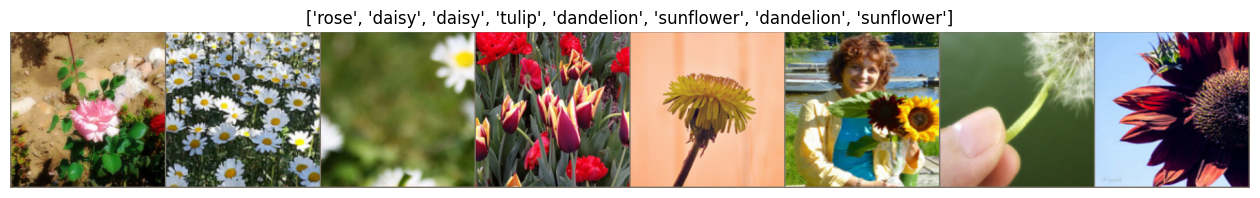

In [22]:
img_show(inp, title=[class_names[x] for x in labels])

In [23]:
model = models.resnet18(pretrained=True)

c:\Users\Andrew\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Andrew\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Andrew/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 37.9MB/s]


#### Check the input feature size for our linear layer
The final layer of our pre-trained model will be the input to a final Linear layer we need to add. To get the number of input features for our linear layer, we check the value of model.fc.in_features

In [24]:
num_ftrs = model.fc.in_features
num_ftrs

512

#### Adding last layer,
We have 5 discrete output labels, hence last layer must 5 output neurons(nodes)

In [26]:
model.fc = nn.Linear(num_ftrs, 5)

#### The criterion to minimize in the loss function
Given this is a classification model, we will look to minimize the cross-entropy loss

In [27]:
criterion = nn.CrossEntropyLoss()

### Set up the optimizer
We define a simple SGD optimizer with momentum which accelerate gradients vectors in the right directions and hence leads to faster converging

In [28]:
import torch.optim as optim

optimizer = optim.SGD(model.parameters(), 
                      lr=0.001, 
                      momentum=0.9)

#### Decay Learning Rate by a factor of 0.1 every 7 epochs
This will speed up the computation as we don't need the same learning rate while getting closer to convergence

In [29]:
from torch.optim import lr_scheduler

exp_lr_scheduler = lr_scheduler.StepLR(optimizer, 
                                       step_size=7, 
                                       gamma=0.1)

#### A function to calculate the loss and accuracy of our model
calculate_accuracy will calculate loss and accuracy per epoch and will be used in training as well as while testing

In [30]:
def calculate_accuracy(phase, running_loss, running_corrects):

    epoch_loss = running_loss / len(image_datasets[phase])
    epoch_acc = running_corrects.double() / len(image_datasets[phase])

    print('{} Loss: {:.4f} Acc: {:.4f}'.format( phase, epoch_loss, epoch_acc))
    
    return (epoch_loss, epoch_acc)

#### Define the training phase
This will be the training operation performed at each epoch

* <b>scheduler.step()</b> will set up the scheduler for each step in order to decay the learning rate
* <b>model.train()</b> will set the pre-trained model into training mode. This is only available for pre-trained models
* <b>running_loss</b> will keep track of the loss at each iteration
* <b>running_corrects</b> keeps a count of the number of correct predictions which will be used to calculate the accuracy of the model
<br />
* By setting <b>torch.set_grad_enabled(True)</b> we are enabling Autograd
* <b>outputs</b> is the list probabilities for each possible label for the batch of images (which are the inputs). We use torch.max() to get the index of the highest probability label for each image in the batch

In [31]:
def phase_train(model, criterion, optimizer, scheduler):
    
    scheduler.step()
    model.train()
    running_loss = 0.0
    running_corrects = 0
    
    
    for inputs, labels in dataloaders['train']:

        optimizer.zero_grad()
        
        with torch.set_grad_enabled(True):
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
    
    calculate_accuracy('train', running_loss, running_corrects) 

In [32]:
import copy

#### Initialize the value of accuracy to 0
This will be used in the test phase to calculate the accuracy of the model

In [33]:
best_acc = 0.0

#### Define the test phase
This will be the test operation performed at each epoch

* <b>model.eval()</b> will set the pre-trained model into evaluation mode. This is only available for pre-trained models
* <b>running_loss</b> will keep track of the loss at each iteration
* <b>running_corrects</b> keeps a count of the number of correct predictions which will be used to calculate the accuracy of the model
<br />
* By setting <b>torch.no_grad()</b> we are disabling Autograd
* <b>outputs</b> is the list probabilities for each possible label for the batch of images (which are the inputs). We use torch.max() to get the index of the highest probability label for each image in the batch
<br />

Once the accuracy is calculated, we check to see if the accuracy in this has improved since the previous epoch. If not, we do not adjust the weights of the model. If so, we set the weights of the model to be the ones calculated in this epoch and return those values

In [34]:
def phase_test(model, criterion, optimizer):
    
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    global best_acc
    
    for inputs, labels in dataloaders['test']:

        optimizer.zero_grad()
        
        with torch.no_grad():
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        
    epoch_loss, epoch_acc = calculate_accuracy('test', running_loss, running_corrects)
    
    if epoch_acc > best_acc:
        best_acc = epoch_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        
    return best_model_wts

#### We build upon our pre-trained model
* we initialize the <b>best_model_wts</b> from the weights of the pre-trained model
* perform the training and testing and update the model weights if it has supplied improved accuracy in the epoch

In [35]:
def build_model(model, criterion, optimizer, scheduler, num_epochs=10):
    
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        phase_train(model, criterion, optimizer, scheduler)
        best_model_wts = phase_test(model, criterion, optimizer)
        print()
    
    print('Best test Acc: {:4f}'.format(best_acc))

    model.load_state_dict(best_model_wts)
    return model

#### Call the build_model function
We set the number of epochs to 1 here, as it takes about 30 minutes for this model to be built. When running on a cloud platform VM with a GPU, we were able to run about 6 epochs and got accuracy levels upwards of 90%

In [36]:
model = build_model(model, 
                    criterion, 
                    optimizer, 
                    exp_lr_scheduler, 
                    num_epochs=1)

Epoch 0/0
----------


C:\Users\Andrew\AppData\Local\Temp\ipykernel_9328\1095663124.py:3: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


train Loss: 0.7233 Acc: 0.7255
test Loss: 0.4220 Acc: 0.8565

Best test Acc: 0.856481


#### Lets check how our model performs
We will take one batch from test datasets (and we have batches of 8 images) and we will predict the correct label


In [ ]:
with torch.no_grad():
    
    inputs, labels = iter(dataloaders['test']).next()
    inp = torchvision.utils.make_grid(inputs)
    
    outputs = model(inputs)
    _, preds = torch.max(outputs, 1)
    
    for j in range(len(inputs)):
        inp = inputs.data[j]
        img_show(inp, 'predicted:' + class_names[preds[j]])

### Freezing a model's layers
Here, we freeze all the layers in the network except the final layer.<br> 
We need to set requires_grad == False to freeze the parameters so that the gradients are not computed in backward().

In [ ]:
frozen_model = models.resnet18(pretrained=True)

In [ ]:
for param in frozen_model.parameters():
    param.requires_grad = False

#### We add the final layer which is not frozen

In [ ]:
frozen_model.fc = nn.Linear(num_ftrs, 5)

#### Add an optimizer - for only the final layer
There is no gradient calculation for the other layers, so we cannot use an optimizer for those

In [ ]:
optimizer = optim.SGD(frozen_model.fc.parameters(), 
                      lr=0.001, 
                      momentum=0.9)

#### Create a scheduler for this model
Just like with the earlier model, we attach a scheduler to this optimizer in order to slow down the learning rate

In [ ]:
exp_lr_scheduler = lr_scheduler.StepLR(optimizer, 
                                       step_size=7, 
                                       gamma=0.1)

#### The loss calculation is the same CrossEntropyLoss as earlier
This is just included here as a reminder as we are not changing the definition

In [ ]:
criterion = nn.CrossEntropyLoss()

#### Reset the best_acc score
This is so that the new frozen model can start from scratch

In [ ]:
best_acc = 0.0

#### Build the new model with the frozen layers
This is similar to what we did previously. Except this time, the gradient calculation is turned off for the parameters when a call is made to backward()

In [ ]:
frozen_model = build_model(frozen_model, 
                           criterion, 
                           optimizer, 
                           exp_lr_scheduler, 
                           num_epochs=1)

Epoch 0/0
----------
train Loss: 0.8167 Acc: 0.6924
test Loss: 0.5352 Acc: 0.7824

Best test Acc: 0.782407


#### We test a batch of flowers on this new model

In [ ]:
with torch.no_grad():
    
    inputs, labels = iter(dataloaders['test']).next()
    inp = torchvision.utils.make_grid(inputs)
    
    outputs = frozen_model(inputs)
    _, preds = torch.max(outputs, 1)
    
    for j in range(len(inputs)):
        inp = inputs.data[j]
        img_show(inp, 'predicted:' + class_names[preds[j]])

# Text Classification Exercise - Predict Gender

In [8]:
names_data = pd.read_csv(r"D:\PluraSight\PyTorch\4 Deep Learning Models\datasets\gender_by_names\names.csv")

names_data.describe().transpose()

,count,unique,top,freq
Name,10132,9543,Jaime,2
Gender,10132,2,Female,6950


In [9]:
import random 

names_data = names_data.drop_duplicates(subset=['Name'], 
                                        keep=random.choice(['first', 'last']))
len(names_data)

9543

In [10]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
names_data['Gender'] = le.fit_transform(names_data['Gender'])
names_data.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Gender,9543.0,0.271717,0.444868,0.0,0.0,0.0,1.0,1.0


#### Create a list containing the genders
These are the genders available in our dataset

In [11]:
genders=['Female', 'Male']

#### Getting all possible letters
This will allow us to create a one-hot-encoded tensor for the names

In [12]:
import string
all_letters = string.ascii_letters + " .,;'"
n_letters = len(all_letters)
all_letters

"abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ .,;'"

#### Function to convert name in tensors 
This effectively performs one-hot-encoding

In [13]:
import torch

def name_to_tensor(name):
    name_in_tensor = torch.zeros(len(name), 1, n_letters)
    for i, letter in enumerate(name):
        name_in_tensor[i][0][all_letters.find(letter)] = 1
        
    return name_in_tensor

In [15]:
print(name_to_tensor('Andrew').shape)
name_to_tensor('Aa')

torch.Size([6, 1, 57])


tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]],

        [[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0.]]])

In [38]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(RNN, self).__init__()

        self.hidden_size = hidden_size
        self.i2h = nn.Linear(input_size + hidden_size, hidden_size)
        self.i2o = nn.Linear(input_size + hidden_size, output_size)
        self.dropout = nn.Dropout(0.2)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, input, hidden):

        combined = torch.cat((input, hidden), 1)
        hidden = self.i2h(combined)
        output = self.i2o(combined)
        output = self.dropout(output)
        output = self.softmax(output)

        return output, hidden
    
    def initHidden(self):
        return torch.zeros(1, self.hidden_size)
   

In [20]:
n_hidden = 128
n_gender = len(genders)

In [39]:
rnn_gender = RNN(n_letters, n_hidden, n_gender)

iter = 10000
criterion = nn.NLLLoss()
lr = 1e-3

In [23]:
def output_to_gender(output):
    top_n, top_i = output.topk(1)
    pred_i = top_i[0].item()
    pred = genders[pred_i]
    return pred 

In [43]:
for iteration in range(1 , iter +1):

    i = random.randint(0, len(names_data) - 1)
    
    name = names_data.iloc[i][0]
    name_in_tensor = name_to_tensor(name)
    
    gender = names_data.iloc[i][1]
    gender_in_tensor = torch.LongTensor([gender])
    
    hidden = rnn_gender.initHidden()
    rnn_gender.zero_grad()

    for i in range(name_in_tensor.size()[0]):
        output, hidden = rnn_gender(name_in_tensor[i], hidden)

    loss = criterion(output, gender_in_tensor)
    loss.backward()
    
    for p in rnn_gender.parameters():
        p.data.add_(-lr, p.grad.data)

    if iteration% 500 == 0:
        
        pred = output_to_gender(output)
        
        correct = '✓' if pred == genders[gender] else '✗ (%s)' % genders[gender]
        print('iters- %d %d%% (%s) Name- %s Gender- %s %s' % \
              (iteration, iteration/iteration*100, loss.item(), name, pred, correct))


C:\Users\Andrew\AppData\Local\Temp\ipykernel_20388\2264823318.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  name = names_data.iloc[i][0]
C:\Users\Andrew\AppData\Local\Temp\ipykernel_20388\2264823318.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  gender = names_data.iloc[i][1]


iters- 500 100% (0.8274666666984558) Name- Wojciech Gender- Female ✗ (Male)
iters- 1000 100% (0.29377758502960205) Name- Adrianne Gender- Female ✓
iters- 1500 100% (0.3106732964515686) Name- Carolee Gender- Female ✓
iters- 2000 100% (1.2656375169754028) Name- Wilt Gender- Female ✗ (Male)
iters- 2500 100% (0.18391336500644684) Name- Junina Gender- Female ✓
iters- 3000 100% (0.4950155019760132) Name- Marvis Gender- Female ✓
iters- 3500 100% (0.9482885599136353) Name- Rustie Gender- Female ✗ (Male)
iters- 4000 100% (0.17312656342983246) Name- Yolonda Gender- Female ✓
iters- 4500 100% (0.1435035765171051) Name- Fayina Gender- Female ✓
iters- 5000 100% (0.9612385034561157) Name- Morrie Gender- Female ✗ (Male)
iters- 5500 100% (0.15850217640399933) Name- Giralda Gender- Female ✓
iters- 6000 100% (0.1575927585363388) Name- Keira Gender- Female ✓
iters- 6500 100% (0.3774552047252655) Name- Bellamy Gender- Female ✓
iters- 7000 100% (0.4622066915035248) Name- Brier Gender- Female ✓
iters- 7500 1

#### Perform a test using 10,000 randomly selected names
We peform steps similar to what was done in training. 
* pick a name at random, conver to tensor
* convert the label to a tensor
* initialize the RNN's hidden layers
* make a prediction for each additional character of the name and then get the final prediction after all the characters have been fed in

After this, we create lists with the real and predicted values of gender. We will use these to plot a confusion matrix to check the accuracy. 

In [45]:
n_confusion = 10000

prediction=[]
actual = []

for _ in range(n_confusion):

    i = random.randint(0, len(names_data) - 1)
    
    name = names_data.iloc[i][0]
    name_in_tensor = name_to_tensor(name)
    
    gender_idx = names_data.iloc[i][1]
    gender_in_tensor = torch.LongTensor([gender_idx])
        
    hidden = rnn_gender.initHidden()

    for j in range(name_in_tensor.size()[0]):
        output, hidden = rnn_gender(name_in_tensor[j], hidden)
    
    pred = output_to_gender(output)
    
    prediction.append(pred)
    actual.append(genders[gender_idx])

C:\Users\Andrew\AppData\Local\Temp\ipykernel_20388\374481752.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  name = names_data.iloc[i][0]
C:\Users\Andrew\AppData\Local\Temp\ipykernel_20388\374481752.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  gender_idx = names_data.iloc[i][1]


In [47]:
matrix = confusion_matrix(actual, prediction, labels=genders)
matrix

array([[7279,    3],
       [2705,   13]])

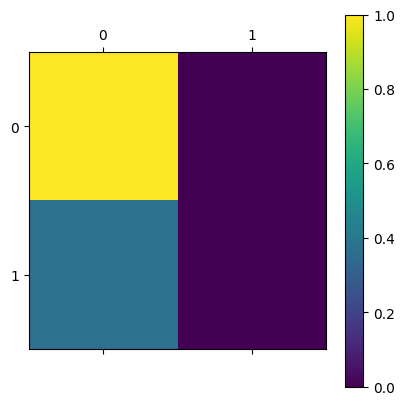

In [49]:
normalized_matrix = (matrix - matrix.min()) / (matrix.max() - matrix.min())

plt.matshow(normalized_matrix)
plt.colorbar()
plt.show()